# 01. Розвідувальний аналіз даних (EDA)

**Мета ноутбука:** зрозуміти, *хто* йде від оператора і *чому*, ще до того, як будувати модель.
Кожна гіпотеза, яку ми тут знайдемо, потім стане ознакою в `src/churn/features.py`.

**Датасет:** [IBM Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d) — 7 043 клієнти
вигаданого телеком-оператора, 21 колонка: демографія, підключені послуги, договір, оплата
та ціль `Churn` (чи пішов клієнт протягом останнього місяця).

План:
1. Перший погляд на дані та їх якість
2. Цільова змінна і дисбаланс класів
3. Числові ознаки: стаж, платежі
4. Категоріальні ознаки: договір, оплата, послуги
5. Взаємодії та кореляції
6. Висновки → ознаки для моделі

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from churn.data import clean, download_data, load_raw

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)

raw = load_raw(download_data())
raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Перший погляд на дані

Перевіряємо типи колонок і пропуски. Типова пастка цього датасету: `TotalCharges` має бути числом,
але pandas читає його як `object` (рядок).

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
blank = raw["TotalCharges"].str.strip() == ""
print(f"Порожніх TotalCharges: {blank.sum()}")
raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Порожніх TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Що бачимо:** 11 клієнтів мають `TotalCharges = " "`, і в усіх `tenure = 0`. Це нові клієнти,
які ще не отримали жодного рахунку. Тож це не «пропуск», а нуль. Видаляти рядки чи заповнювати
медіаною тут було б помилкою: функція `clean()` ставить 0 і перетворює ціль на 0/1.

> 💡 Перш ніж заповнювати пропуски, з'ясуйте, **чому** вони виникли. Причина часто підказує правильне значення.

In [4]:
df = clean(raw)
print("Дублікатів customerID:", df["customerID"].duplicated().sum())
df.describe().T

Дублікатів customerID: 0


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80
Churn,7043.0,0.265370,0.441561,0.00,0.00,0.00,1.00,1.00


## 2. Цільова змінна

Відтік — **26.5%** клієнтів. Класи незбалансовані (приблизно 1:3), і це впливає на три речі:
* **Accuracy вводить в оману.** Модель «ніхто не піде» має 73.5% accuracy і нульову користь.
  Тому дивимось на ROC-AUC, PR-AUC, precision/recall.
* **Розбиття має бути стратифікованим**, щоб частка відтоку була однакова в train і test.
* **Моделям варто «нагадати» про рідший клас** через `class_weight="balanced"` або `scale_pos_weight`.

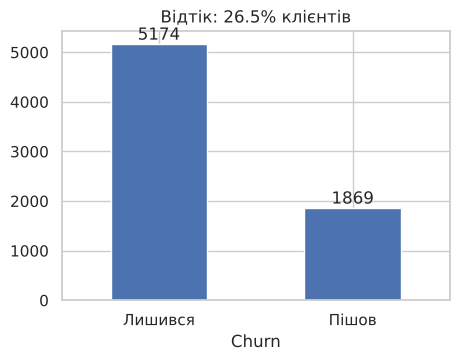

In [5]:
ax = df["Churn"].map({0: "Лишився", 1: "Пішов"}).value_counts().plot.bar(rot=0, figsize=(5, 3.5))
ax.bar_label(ax.containers[0])
ax.set_title(f"Відтік: {df['Churn'].mean():.1%} клієнтів")
plt.show()

## 3. Числові ознаки

Три числові колонки: `tenure` (місяців з оператором), `MonthlyCharges` і `TotalCharges`.
Порівнюємо розподіли для тих, хто пішов, і тих, хто лишився.

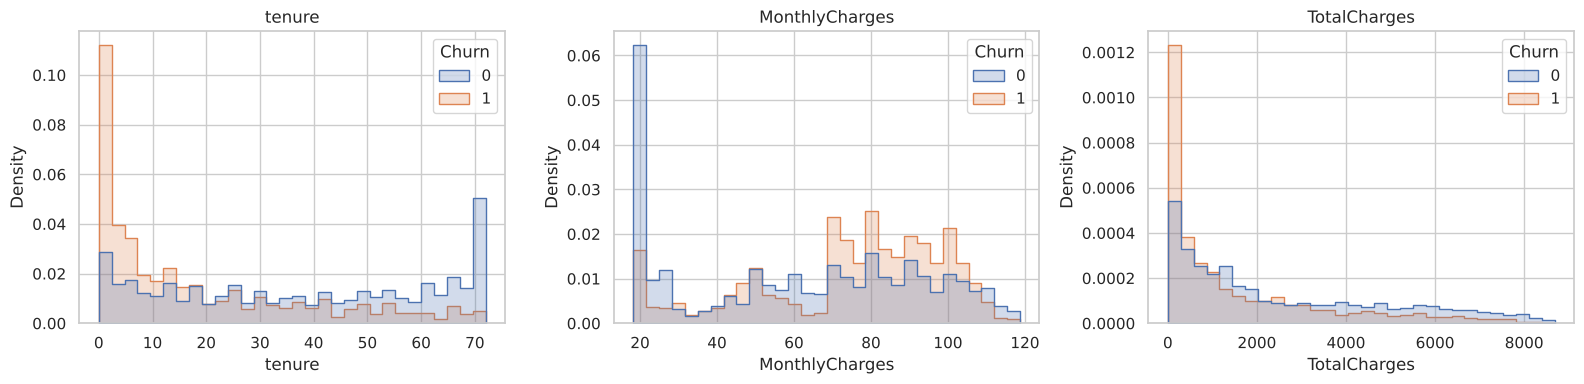

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df, x=col, hue="Churn", stat="density", common_norm=False,
                 element="step", bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Висновки:**
* **`tenure` — найсильніший числовий сигнал.** Ті, хто йде, роблять це в перші місяці.
  Після 2 років відтік рідкісний. Звідси ознака `is_new_customer` (tenure ≤ 6).
* **`MonthlyCharges`:** серед тих, хто пішов, більше клієнтів з високим рахунком (70–110 $).
* **`TotalCharges`** ≈ `tenure × MonthlyCharges`, тобто вона здебільшого дублює інформацію (див. кореляції нижче).

Подивимось на ризик відтоку залежно від стажу детальніше.

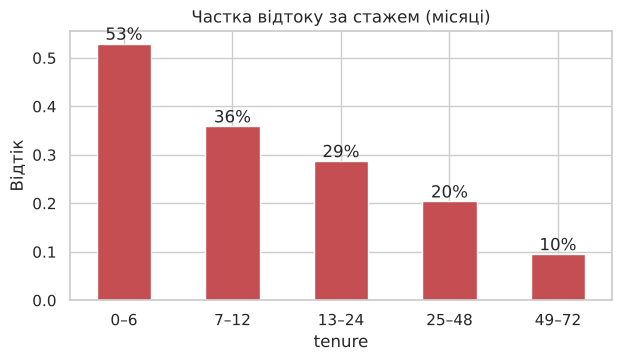

,mean,size
tenure,,
0–6,0.529372,1481
7–12,0.358865,705
13–24,0.287109,1024
25–48,0.203890,1594
49–72,0.095132,2239


In [7]:
tenure_bins = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
                     labels=["0–6", "7–12", "13–24", "25–48", "49–72"])
rate = df.groupby(tenure_bins, observed=True)["Churn"].agg(["mean", "size"])
ax = rate["mean"].plot.bar(rot=0, figsize=(7, 3.5), color="C3")
ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in rate["mean"]])
ax.set(title="Частка відтоку за стажем (місяці)", ylabel="Відтік", xlabel="tenure")
plt.show()
rate

Новачки (0–6 міс.) йдуть у **~53%** випадків, а ветерани (4+ роки) лише в **~9.5%**.
Для бізнесу це означає, що перші пів року клієнта є критичним періодом для програм утримання.

## 4. Категоріальні ознаки

Для кожної категорії рахуємо частку відтоку. Пунктирна лінія показує середній рівень (26.5%).

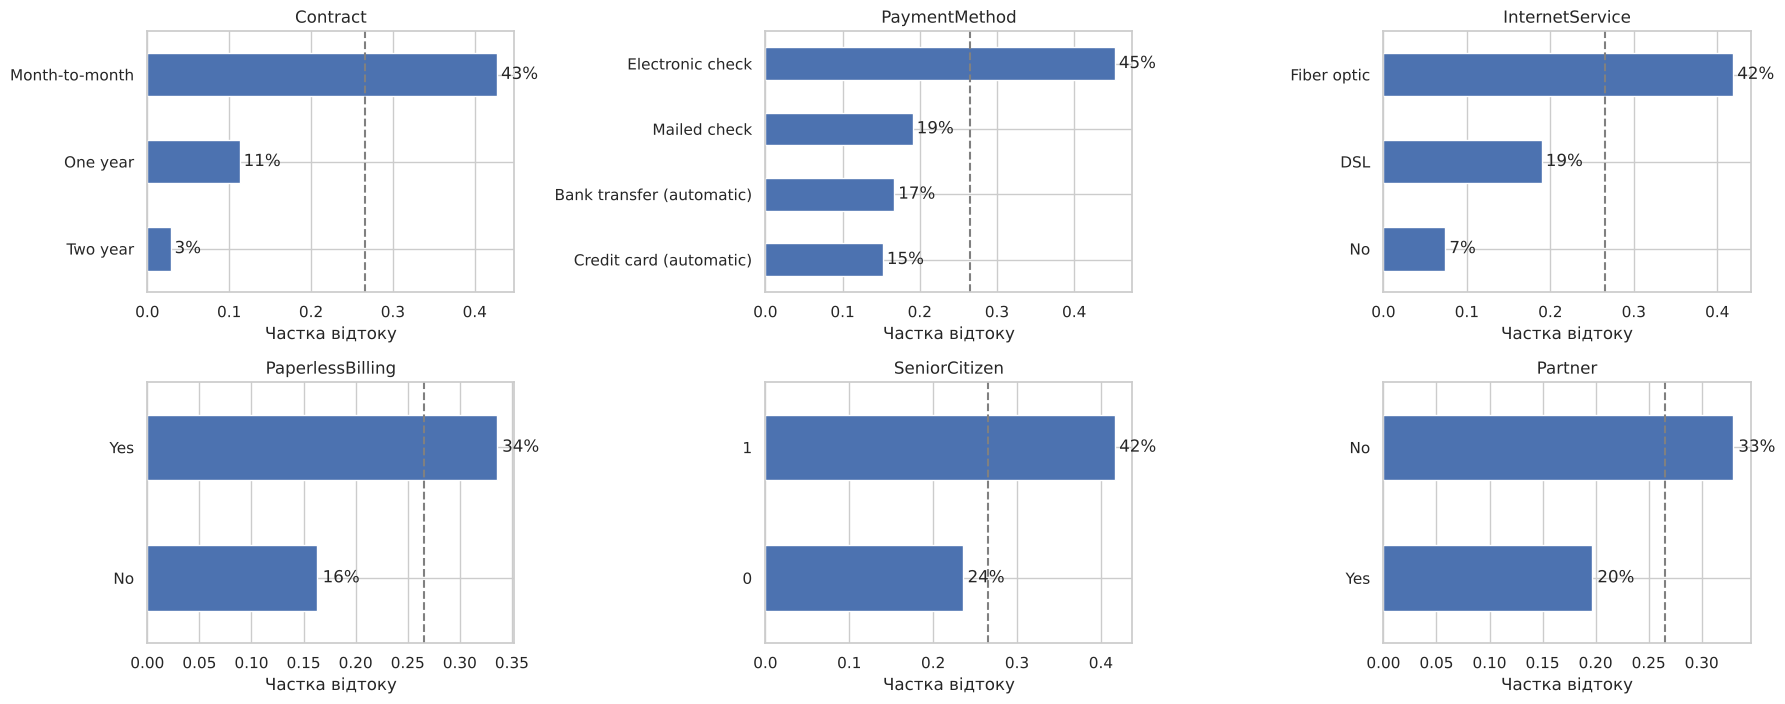

In [8]:
def churn_rate_plot(cols, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.6 * nrows))
    for ax, col in zip(np.ravel(axes), cols):
        r = df.groupby(col)["Churn"].mean().sort_values()
        r.plot.barh(ax=ax, color="C0")
        ax.axvline(df["Churn"].mean(), ls="--", color="grey")
        ax.set(title=col, xlabel="Частка відтоку", ylabel="")
        for i, v in enumerate(r):
            ax.text(v + 0.005, i, f"{v:.0%}", va="center")
    for ax in np.ravel(axes)[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

churn_rate_plot(["Contract", "PaymentMethod", "InternetService",
                 "PaperlessBilling", "SeniorCitizen", "Partner"])

**Найсильніші сигнали:**
* **Договір.** Помісячний договір дає ~43% відтоку, дворічний лише ~3%. Людину нічого не тримає,
  тому вона йде. Ознака `is_month_to_month`.
* **Electronic check** дає ~45% відтоку проти ~15–17% для автоматичних платежів. Автоплатіж створює
  інерцію, а ручна оплата щомісяця нагадує про витрати. Ознака `is_electronic_check`.
* **Fiber optic** дає ~42%, попри те що це «кращий» інтернет. Ймовірна причина — висока ціна або проблеми якості.
  Ознака `has_fiber`.
* Пенсіонери, клієнти без партнера та з електронними рахунками також йдуть частіше.

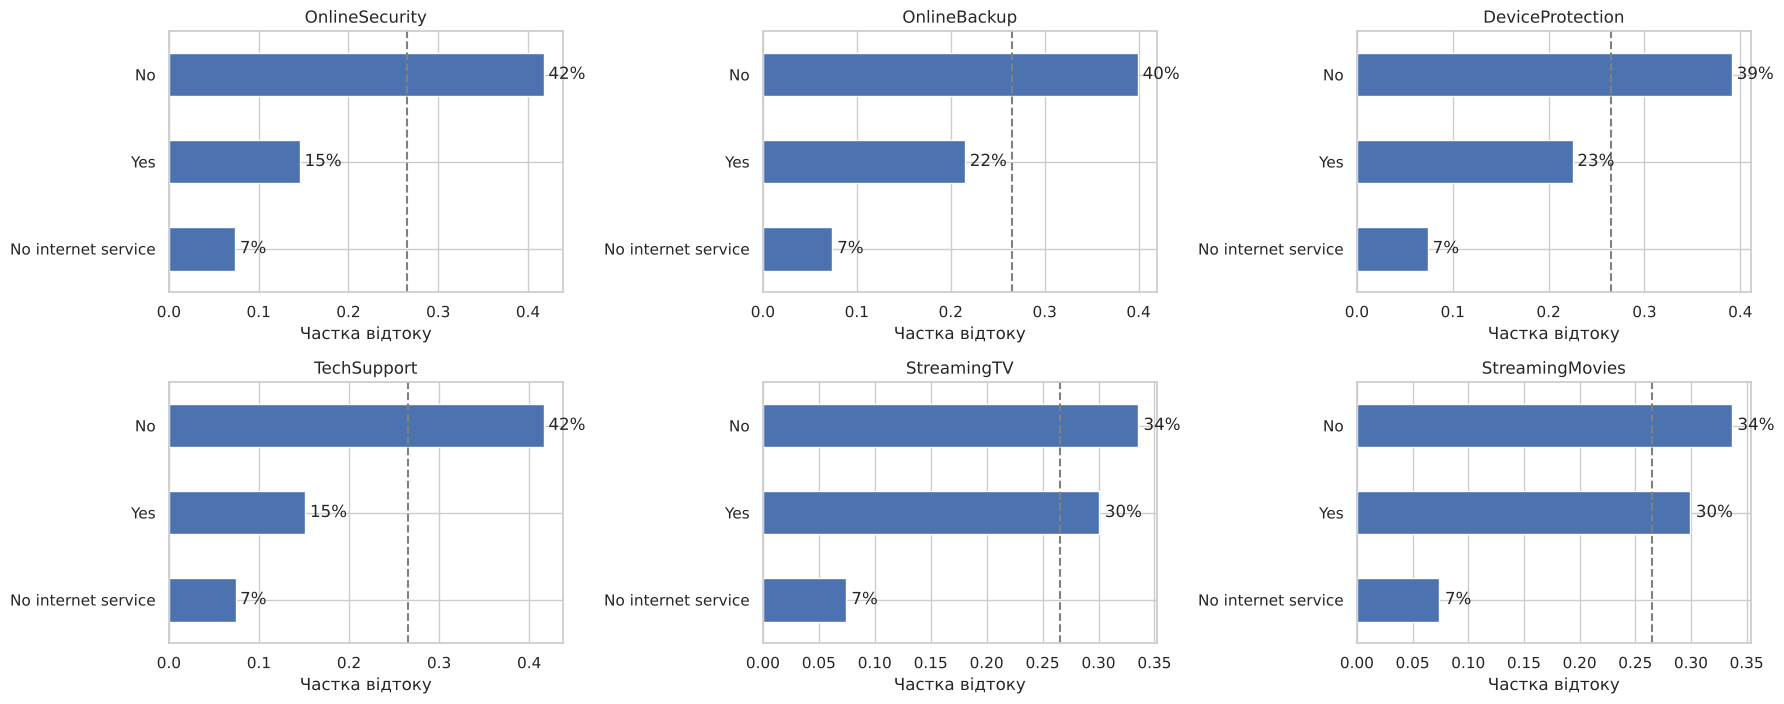

In [9]:
churn_rate_plot(["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"])

**Додаткові послуги:**
* Клієнти **без OnlineSecurity** або **без TechSupport** йдуть майже втричі частіше (~42% проти ~15%).
  Якщо немає жодної з цих двох послуг, відтік ~49% проти ~17%. Звідси ознака `no_protection`.
* Стримінг майже не впливає на відтік.
* Кожна послуга додає «зв'язок» з оператором. Перевіримо гіпотезу, що більше послуг означає менший відтік.

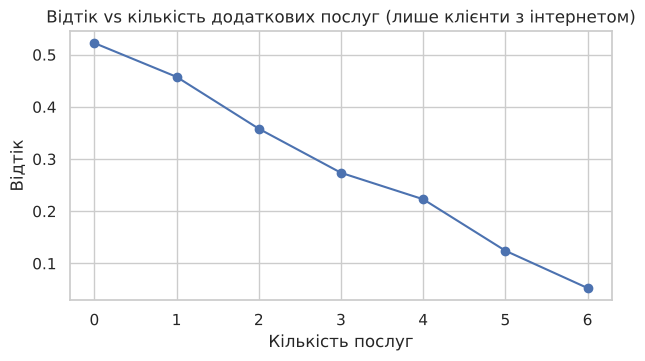

,mean,size
num_addon_services,,
0,0.522367,693
1,0.457557,966
2,0.358180,1033
3,0.273703,1118
4,0.223005,852
5,0.124343,571
6,0.052817,284


In [10]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
          "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_addon_services"] = (df[addons] == "Yes").sum(axis=1)
internet = df[df["InternetService"] != "No"]
r = internet.groupby("num_addon_services")["Churn"].agg(["mean", "size"])
ax = r["mean"].plot(marker="o", figsize=(7, 3.5))
ax.set(title="Відтік vs кількість додаткових послуг (лише клієнти з інтернетом)",
       xlabel="Кількість послуг", ylabel="Відтік")
plt.show()
r

Гіпотеза підтверджується: з 0–1 послугою відтік ~46–52%, з 5–6 лише ~5–12%, і спад монотонний.
`num_addon_services` стає однією з наших ознак.

## 5. Взаємодії та кореляції

Договір і стаж сильно пов'язані: довгі договори укладають лояльні клієнти. Подивимось на них разом.

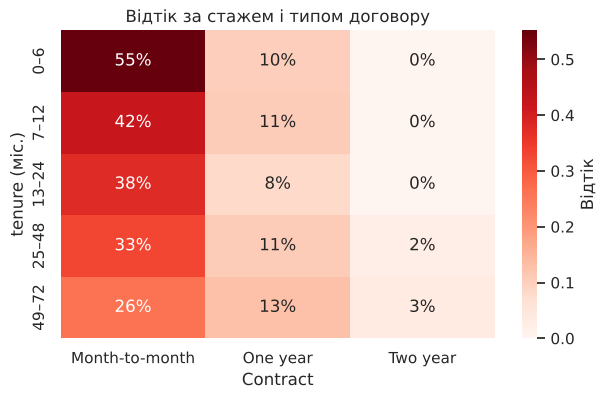

In [11]:
pivot = df.pivot_table(index=tenure_bins, columns="Contract", values="Churn", aggfunc="mean",
                       observed=True)
plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds", cbar_kws={"label": "Відтік"})
plt.title("Відтік за стажем і типом договору")
plt.ylabel("tenure (міс.)")
plt.show()

Навіть серед новачків договір на 1–2 роки різко знижує відтік. Ефекти частково незалежні,
тому моделі корисно бачити обидві ознаки. Дерева (XGBoost, LightGBM) знаходять такі
взаємодії автоматично.

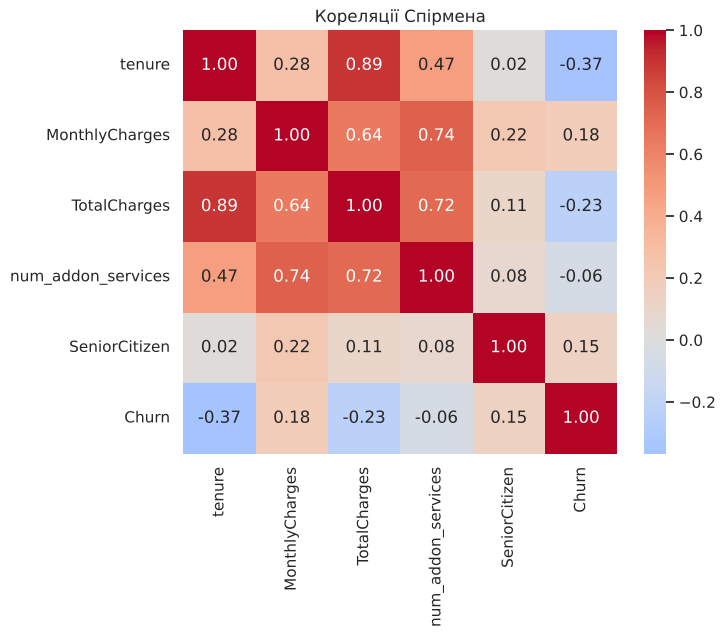

In [12]:
num = df[["tenure", "MonthlyCharges", "TotalCharges", "num_addon_services", "SeniorCitizen", "Churn"]]
plt.figure(figsize=(7, 5.5))
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Кореляції Спірмена")
plt.show()

* `TotalCharges` дуже сильно корелює з `tenure` (ρ ≈ 0.89). Мультиколінеарність не заважає деревам,
  але робить коефіцієнти логістичної регресії менш стабільними. Регуляризація (`C=0.5`) це пом'якшує.
* `tenure` має найсильнішу (від'ємну) кореляцію з відтоком.

### Ознака `charge_delta`
Якщо поточний `MonthlyCharges` вищий за середній фактичний платіж (`TotalCharges / tenure`),
рахунок клієнта зростав; якщо нижчий, то падав. Гіпотеза: зміна ціни є тригером відтоку.

In [13]:
safe = df["tenure"].replace(0, np.nan)
df["charge_delta"] = df["MonthlyCharges"] - (df["TotalCharges"] / safe).fillna(df["MonthlyCharges"])
q = pd.qcut(df["charge_delta"], 5, duplicates="drop")
df.groupby(q, observed=True)["Churn"].mean().to_frame("Відтік")

,Відтік
charge_delta,
"(-18.901, -1.523]",0.308020
"(-1.523, -0.299]",0.163352
"(-0.299, 0.285]",0.367637
"(0.285, 1.535]",0.169744
"(1.535, 19.125]",0.317956


Результат **не монотонний**, і це чесний урок EDA: гіпотеза підтвердилась лише частково.
Відтік вищий на обох краях (рахунок суттєво виріс *або* впав), а також у середньому кошику,
куди потрапляють клієнти з `tenure` ≤ 1, у яких дельта рівно 0 за побудовою.
Лінійна модель таку U-подібну залежність не вловить, а дерева вловлять. Ознаку лишаємо,
а чи корисна вона, покаже SHAP у наступному ноутбуці.

## 6. Висновки

| Спостереження з EDA | Ознака в `features.py` |
|---|---|
| Помісячний договір дає ~43% відтоку | `is_month_to_month` |
| Ризик найвищий у перші 6 місяців | `is_new_customer`, `tenure_years` |
| Electronic check дає ~45% відтоку | `is_electronic_check` |
| Fiber optic, попри якість, дає ~42% | `has_fiber` |
| Без захисту/підтримки відтік майже втричі вищий | `no_protection` |
| Більше послуг означає менший відтік | `num_addon_services` |
| Зміна рахунку (U-подібний зв'язок) | `charge_delta`, `avg_monthly_spend` |

**Якість даних:** 11 порожніх `TotalCharges` замінено на 0 (нові клієнти), дублікатів немає.

**Рішення щодо моделювання:**
* метрики ROC-AUC і PR-AUC замість accuracy;
* стратифікований split і крос-валідація;
* ваги класів для дисбалансу;
* поріг класифікації обираємо за бізнес-цінністю, а не 0.5.

Далі: [`02_modeling_and_explainability.ipynb`](02_modeling_and_explainability.ipynb).